# 01. Аналіз корпусу Шевченка

Перевіряємо `poems_uk.jsonl` (результат `kobzarai.scrape` і `kobzarai.filter`): статистика, токени, якість, вибірка для ручного читання.

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/processed")
df = pd.read_json(DATA / "poems_uk.jsonl", lines=True)
df["chars"] = df["text"].str.len()
df["lines"] = df["text"].map(lambda t: sum(bool(l.strip()) for l in t.split("\n")))
df["words"] = df["text"].str.split().str.len()
df[["title", "genre", "year", "chars", "lines"]].head()

,title,genre,year,chars,lines
0,А нумо знову віршувать,вірш,NaN,670,31
1,Барвінок цвів і зеленів,вірш,NaN,188,9
2,"Буває, в неволі іноді згадаю",вірш,NaN,3793,134
3,"Буває, іноді старий",вірш,NaN,512,21
4,Бували войни й військовії свари,вірш,NaN,624,24


## Загальна статистика

Текстів: 214
Символів: 481,665  Слів: 82,055  Рядків: 21,592

Жанри:
genre
вірш        180
поема        32
містерія      1
комедія       1

Рік відомий для 87 із 214


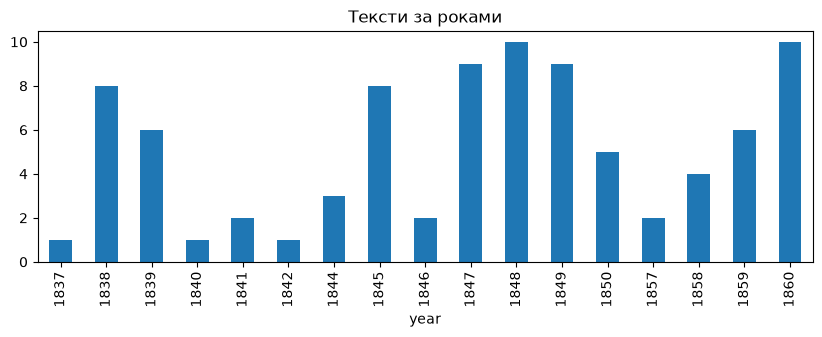

In [2]:
print(f"Текстів: {len(df)}")
print(f"Символів: {df['chars'].sum():,}  Слів: {df['words'].sum():,}  Рядків: {df['lines'].sum():,}")
print("\nЖанри:")
print(df["genre"].value_counts().to_string())
print(f"\nРік відомий для {df['year'].notna().sum()} із {len(df)}")
df["year"].dropna().astype(int).value_counts().sort_index().plot.bar(figsize=(10, 3), title="Тексти за роками")
plt.show()

## Розмір у токенах

Токенізатор майбутньої моделі показує, скільки даних реально є для донавчання.

In [3]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
df["tokens"] = [len(ids) for ids in tok(df["text"].tolist(), add_special_tokens=False)["input_ids"]]
total = df["tokens"].sum()
print(f"Токенів: {total:,}; токенів на слово: {total / df['words'].sum():.2f}")
print(f"Найдовший текст: {df['tokens'].max():,} токенів")
print(f"Текстів довше 2048 токенів: {(df['tokens'] > 2048).sum()}")

Токенів: 253,632; токенів на слово: 3.09
Найдовший текст: 31,604 токенів
Текстів довше 2048 токенів: 33


## Розподіл довжин і викиди

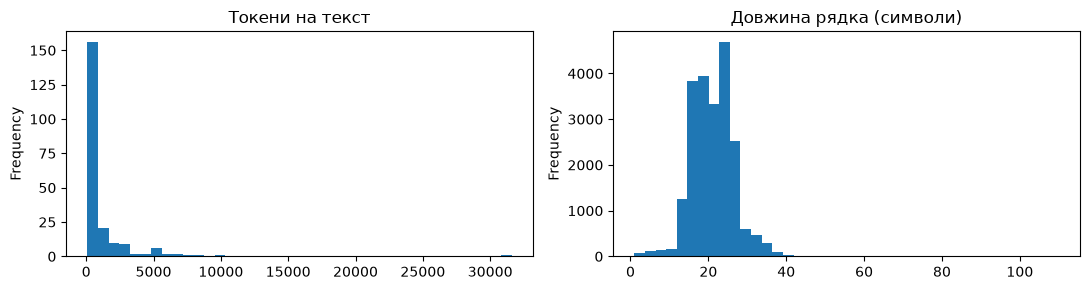

Найдовші:
                         title   genre  tokens
                     Гайдамаки   поема   31604
                         Марія   поема    9824
                      Катерина   поема    8435
                     Невольник   поема    7928
                       Неофіти   поема    6996
Сон ("У всякого своя доля...") комедія    6794
                      Наймичка   поема    6091
                        Відьма   поема    5648

Найкоротші:
                        title genre  tokens
              Встала весна...  вірш      88
       Дівча любе, чорнобриве  вірш      96
   Та не дай, господи, нікому  вірш      99
      Барвінок цвів і зеленів  вірш     105
Мій боже милий, знову лихо!..  вірш     110
                 Полюбилася я  вірш     115
   На батька бісового я трачу  вірш     117
         Ой, сяду я під хатою  вірш     123


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
df["tokens"].plot.hist(bins=40, ax=axes[0], title="Токени на текст")
line_len = [len(l) for t in df["text"] for l in t.split("\n") if l.strip()]
pd.Series(line_len).plot.hist(bins=40, ax=axes[1], title="Довжина рядка (символи)")
plt.tight_layout()
plt.show()

print("Найдовші:")
print(df.nlargest(8, "tokens")[["title", "genre", "tokens"]].to_string(index=False))
print("\nНайкоротші:")
print(df.nsmallest(8, "tokens")[["title", "genre", "tokens"]].to_string(index=False))

## Перевірка якості

Залишки російської та старої орфографії, службові рядки, дублікати.

In [5]:
def suspicious_lines(pattern: str, limit: int = 15) -> pd.DataFrame:
    rx = re.compile(pattern)
    rows = [(r.title, l.strip()) for r in df.itertuples() for l in r.text.split("\n") if rx.search(l)]
    print(f"{pattern!r}: {len(rows)} рядків")
    return pd.DataFrame(rows[:limit], columns=["title", "line"])


display(suspicious_lines(r"[ыэъёѣЫЭЪЁѢ]"))
display(suspicious_lines(r"^\s*[\[\(\*]|\]\s*$"))
display(suspicious_lines(r"^\s*\d+\s*$|^\s*[IVX]+\.?\s*$", 5))

'[ыэъёѣЫЭЪЁѢ]': 27 рядків


,title,line
0,В казематі,Ні про младенческие сны.
1,В казематі,"Меня-то, слышь, и подсмотрили,"
2,Великий льох,Быть беде. Быть беде.
3,Великий льох,"Э… сестрица, много:"
4,Великий льох,Да шесть тысяч в одной версте
5,Великий льох,Я царевыми чинами
6,Великий льох,В самый ад полечу
7,Великий льох,"""Вы што делаете, плуты!!"""
8,Великий льох,"Мошенники, дармоеды!"
9,Кавказ,"Кто даст. главе моей воду, И очесем моим источ..."


'^\\s*[\\[\\(\\*]|\\]\\s*$': 81 рядків


,title,line
0,"Буває, в неволі іноді згадаю","(Ніби мені каже), на всій Україні"
1,В казематі,"(Хоч діялось не восени,"
2,Відьма,(співає)
3,Відьма,(шепче)
4,Відьма,(усміхнувшись)
5,Відьма,(співає тихо)
6,Відьма,(приспівує)
7,Відьма,[Седнев 1847 березня 7]
8,Гайдамаки,(Рідного немає) —
9,Гайдамаки,"(й Ярема розказував,"


'^\\s*\\d+\\s*$|^\\s*[IVX]+\\.?\\s*$': 75 рядків


,title,line
0,В казематі,I
1,В казематі,II
2,В казематі,III
3,В казематі,IV
4,В казематі,V


In [6]:
def line_set(text: str) -> set[str]:
    return {re.sub(r"\s+", " ", l).strip().lower() for l in text.split("\n") if len(l.strip()) >= 15}


sets = [line_set(t) for t in df["text"]]
pairs = []
for i in range(len(df)):
    for j in range(i + 1, len(df)):
        common = len(sets[i] & sets[j])
        if common >= 10:
            share = common / min(len(sets[i]), len(sets[j]))
            if share > 0.5:
                pairs.append((df.title[i], df.title[j], common, round(share, 2)))
print(f"Пар із перетином рядків >50%: {len(pairs)}")
pd.DataFrame(pairs, columns=["a", "b", "common_lines", "share"]).sort_values("share", ascending=False).head(20)

Пар із перетином рядків >50%: 5


,a,b,common_lines,share
2,"Думи мої, думи мої",Стоїть в селі Суботові,81,0.77
3,Молитва,Тим неситим очам,16,0.76
4,"Світає, край неба палає...","Сон (""У всякого своя доля..."")",10,0.67
1,Давидові псалми,Псалми Давидові,170,0.66
0,В казематі,"Мені однаково, чи буду...",12,0.52


## Вибірка для ручного читання

Найважливіший крок: прочитайте кілька текстів очима.

In [7]:
for r in df.sample(5, random_state=7).itertuples():
    print("=" * 60)
    print(f"{r.title} | {r.genre} | {r.year} | {r.date_note}")
    print(r.text[:500])
    print("...")
    print(r.text[-200:])

По улиці вітер віє... | вірш | nan | nan
По улиці вітер віє
Та сніг замітає.
По улиці попідтинню
Вдова шкандибає
Під дзвіницю, сердешная,
Руки простягати
До тих самих, до багатих,
Що сина в солдати
Позаторік заголили.
А думала жити…
Хоч на старість у невістки
В добрі одпочити.
Не довелось. Виблагала
Тую копійчину…
Та пречистій поставила
Свічечку за сина.
...
 тих самих, до багатих,
Що сина в солдати
Позаторік заголили.
А думала жити…
Хоч на старість у невістки
В добрі одпочити.
Не довелось. Виблагала
Тую копійчину…
Та пречистій поставила
Свічечку за сина.
Ликері | вірш | 1860.0 | nan
Моя ти любо! Мій ти друже!
Не ймуть нам віри без хреста,
Не ймуть нам віри без попа
Раби, невольники недужі!
Заснули, мов свиня в калюжі,
В святій неволі! Мій ти друже,
Моя ти любо! Не хрестись,
І не кленись, і не молись
Нікому в світі! Збрешуть люде,
І візантійський Саваоф
Одурить! Не одурить бог,
Карать і миловать не буде:
Ми не раби його — ми люде!
Моя ти любо! усміхнись,
І вольную святую душу,
І руку в

## Частотний словник

Основа для образів і тем у промптах та для перевірки стилю.

In [8]:
words = re.findall(r"[а-яіїєґ'’ʼ-]+", " ".join(df["text"]).lower())
stop = {w for w, _ in Counter(words).most_common(60)}
freq = Counter(w for w in words if w not in stop and len(w) > 3)
pd.DataFrame(freq.most_common(40), columns=["word", "count"]).T

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
word,неначе,лихо,бога,добре,коли,тяжко,старий,море,вона,сльози,...,якби,ніхто,таки,перед,сама,батько,неволі,полі,сонце,хаті
count,120,115,112,111,106,99,98,98,96,95,...,74,74,73,72,71,71,70,70,70,69


## Висновки

_Заповніть після перегляду результатів вище: що ще почистити, що вирішили залишити._